# Unified TCAV Pipeline for DistilBERT on DynaSent

This notebook implements a unified, high-efficiency sequential pipeline covering the Testing with Concept Activation Vectors (TCAV) evaluation methodology for `lxyuan/distilbert-base-multilingual-cased-sentiments-student` on the **DynaSent** dataset (Round 1 and Round 2).

## Step 1: Establish baseline task performance and define the classification score and activation pooling

In this step, we:
1. Set up the execution environment, random seed for reproducibility, and GPU device.
2. Load the DynaSent dataset (Round 1 and Round 2) with standard sentiment label mapping (`positive`: 0, `neutral`: 1, `negative`: 2).
3. Load the pre-trained DistilBERT model and evaluate its baseline classification performance (Accuracy, Macro-F1, Classification Report).
4. Define the sequence token activation pooling function (mean-pooling over non-padding tokens) to extract representations from intermediate Transformer layers.

In [4]:
import os
import re
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score, f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Set random seed for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Label mapping definition
LABEL_MAP = {"positive": 0, "neutral": 1, "negative": 2}
INV_LABEL_MAP = {v: k for k, v in LABEL_MAP.items()}
MODEL_NAME = "lxyuan/distilbert-base-multilingual-cased-sentiments-student"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME).to(device)
model.eval()
print(f"Model {MODEL_NAME} loaded successfully.")

Using device: cuda


'[WinError 10060] Impossibile stabilire la connessione. Risposta non corretta della parte connessa dopo l'intervallo di tempo oppure mancata risposta dall'host collegato' thrown while requesting GET https://huggingface.co/api/models/lxyuan/distilbert-base-multilingual-cased-sentiments-student/tree/main/additional_chat_templates
Retrying in 1s [Retry 1/5].
Loading weights: 100%|██████████| 104/104 [00:00<00:00, 2510.82it/s]


Model lxyuan/distilbert-base-multilingual-cased-sentiments-student loaded successfully.


In [5]:
def load_dynasent_file(filename, labels=None):
    data = []
    if os.path.exists(filename):
        with open(filename, 'r', encoding='utf-8') as f:
            for line in f:
                d = json.loads(line)
                if labels is None or d.get('gold_label') in labels:
                    data.append(d)
    return data

def create_df(r1_data, r2_data):
    return pd.DataFrame({
        'text': [d['sentence'] for d in r1_data] + [d['sentence'] for d in r2_data],
        'round': [1] * len(r1_data) + [2] * len(r2_data),
        'label': [d['gold_label'] for d in r1_data] + [d['gold_label'] for d in r2_data]
    })

BASE_DIR = '../Dataset'
TERNARY_LABELS = ('positive', 'neutral', 'negative')
LABEL_MAP = {'positive': 0, 'neutral': 1, 'negative': 2}

# Load Train, Validation, and Test splits
r1_train = load_dynasent_file(os.path.join(BASE_DIR, 'data/dynasent-v1.1-round01-yelp-train.jsonl'), labels=TERNARY_LABELS)
r2_train = load_dynasent_file(os.path.join(BASE_DIR, 'data/dynasent-v1.1-round02-dynabench-train.jsonl'), labels=TERNARY_LABELS)
df_train = create_df(r1_train, r2_train)
df_train['enc_label'] = df_train['label'].map(LABEL_MAP)

r1_val = load_dynasent_file(os.path.join(BASE_DIR, 'data/dynasent-v1.1-round01-yelp-dev.jsonl'), labels=TERNARY_LABELS)
r2_val = load_dynasent_file(os.path.join(BASE_DIR, 'data/dynasent-v1.1-round02-dynabench-dev.jsonl'), labels=TERNARY_LABELS)
df_val = create_df(r1_val, r2_val)
df_val['enc_label'] = df_val['label'].map(LABEL_MAP)

r1_test = load_dynasent_file(os.path.join(BASE_DIR, 'data/dynasent-v1.1-round01-yelp-test.jsonl'), labels=TERNARY_LABELS)
r2_test = load_dynasent_file(os.path.join(BASE_DIR, 'data/dynasent-v1.1-round02-dynabench-test.jsonl'), labels=TERNARY_LABELS)
df_test = create_df(r1_test, r2_test)
df_test['enc_label'] = df_test['label'].map(LABEL_MAP)

# Consolidated DataFrame for full pipeline access
df_all = pd.concat([df_train, df_val, df_test], ignore_index=True)
df_all['label'] = df_all['enc_label']

print(f"Train samples: {len(df_train)} | Val samples: {len(df_val)} | Test samples: {len(df_test)} | Total: {len(df_all)}")

Train samples: 93553 | Val samples: 4320 | Test samples: 4320 | Total: 102193


Overall Accuracy : 0.4387
Overall Macro-F1 : 0.3916

              precision    recall  f1-score   support

    positive       0.43      0.67      0.52      1440
     neutral       0.30      0.08      0.13      1440
    negative       0.49      0.56      0.52      1440

    accuracy                           0.44      4320
   macro avg       0.41      0.44      0.39      4320
weighted avg       0.41      0.44      0.39      4320

Round 1 -> Accuracy: 0.4344 | Macro-F1: 0.3836


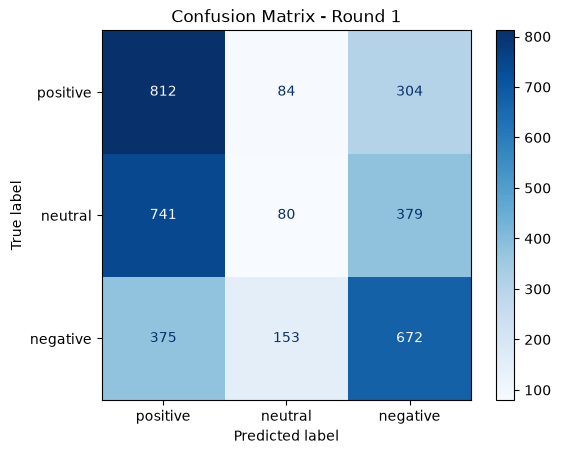

Round 2 -> Accuracy: 0.4597 | Macro-F1: 0.4296


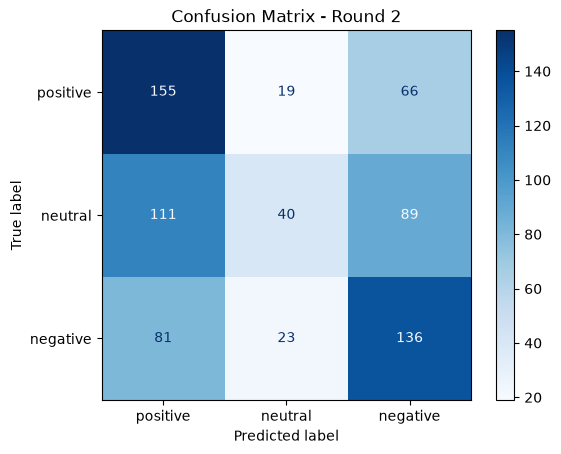

In [6]:
texts = df_test["text"].tolist()
labels = df_test["enc_label"].to_numpy()
rounds = df_test["round"].to_numpy()

batch_size = 64
all_logits, all_preds = [], []

with torch.no_grad():
    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i : i + batch_size]
        enc = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt",
        ).to(device)

        logits = model(**enc).logits.cpu().numpy()
        all_logits.append(logits)
        all_preds.append(logits.argmax(axis=-1))

logits = np.vstack(all_logits)
preds = np.concatenate(all_preds)

print(f"Overall Accuracy : {accuracy_score(labels, preds):.4f}")
print(f"Overall Macro-F1 : {f1_score(labels, preds, average='macro'):.4f}\n")
print(
    classification_report(
        labels, preds, target_names=[model.config.id2label[i] for i in range(3)]
    )
)

# Per-round metric evaluation and confusion matrices
for r in sorted(np.unique(rounds)):
    mask = rounds == r
    print(
        f"Round {r} -> Accuracy: {accuracy_score(labels[mask], preds[mask]):.4f} | "
        f"Macro-F1: {f1_score(labels[mask], preds[mask], average='macro'):.4f}"
    )
    cm = confusion_matrix(labels[mask], preds[mask], labels=[0, 1, 2])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=[model.config.id2label[i] for i in range(3)]
    )
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f"Confusion Matrix - Round {r}")
    plt.show()

In [7]:
# ==============================================================================
# DEFINITION OF CLASSIFICATION SCORE & ACTIVATION POOLING
# ==============================================================================

def mean_pooling(hidden_states: torch.Tensor, attention_mask: torch.Tensor) -> torch.Tensor:
    """
    Applies mean pooling across the token dimension while ignoring [PAD] padding tokens.
    
    Args:
        hidden_states (torch.Tensor): Hidden layer activations of shape (batch_size, seq_len, hidden_dim).
        attention_mask (torch.Tensor): Attention mask of shape (batch_size, seq_len).
        
    Returns:
        torch.Tensor: Sentence-level representation vector of shape (batch_size, hidden_dim).
    """
    # Expand mask to enable broadcasting along hidden_dim -> (batch_size, seq_len, 1)
    input_mask_expanded = attention_mask.unsqueeze(-1).float()
    
    # Sum embeddings of valid (non-padding) tokens only
    sum_embeddings = torch.sum(hidden_states * input_mask_expanded, dim=1)
    
    # Count valid tokens per sentence (clamp to 1e-9 to prevent division by zero)
    sum_mask = input_mask_expanded.sum(dim=1).clamp(min=1e-9)
    
    return sum_embeddings / sum_mask


def get_classification_score(logits: torch.Tensor, target_class: int) -> torch.Tensor:
    """
    Defines the classification score h_k(x) as the unnormalized logit corresponding 
    to target class k. 
    
    Theoretical note: Raw logits are used instead of Softmax probabilities 
    to prevent gradient saturation during CAV computation.
    
    Args:
        logits (torch.Tensor): Model output logits of shape (batch_size, num_classes).
        target_class (int): Index of the target sentiment class (0: positive, 1: neutral, 2: negative).
        
    Returns:
        torch.Tensor: Classification scores for the target class of shape (batch_size,).
    """
    return logits[:, target_class]


# --- Functional correctness test ---
if __name__ == "__main__":
    sample_texts = ["Great service and tasty food!", "The product was bad."]
    enc_test = tokenizer(sample_texts, padding=True, truncation=True, return_tensors="pt").to(device)
    
    with torch.no_grad():
        out_test = model(**enc_test, output_hidden_states=True)
        # hidden_states[1] corresponds to Layer 1 output (post-embedding hidden state)
        pooled_l1 = mean_pooling(out_test.hidden_states[1], enc_test["attention_mask"])
        score_pos = get_classification_score(out_test.logits, target_class=0)
        
    print(f"Pooled activations shape (Layer 1): {pooled_l1.shape}")  # Expected: (2, 768)
    print(f"Classification Score ('positive' class): {score_pos.cpu().numpy()}")

Pooled activations shape (Layer 1): torch.Size([2, 768])
Classification Score ('positive' class): [ 1.7666224 -1.7743614]


# Step 2 — Layer Probing & CAV Validation

In this step, we perform an empirical exploration of DistilBERT hidden layers to select the optimal layer subset for TCAV:
1. **Concept Annotation**: Define regex-based linguistic indicators (`has_negation`, `has_contrast`, `has_strong_polarity`).
2. **Layer Activation Extraction**: Extract mean-pooled activations across all 6 Transformer layers.
3. **Validation Layer Probing**: Evaluate target sentiment classification informativeness (ROC-AUC) across layers on the validation split.
4. **CAV Fitting & Validation**: Train Concept Activation Vectors (CAVs) on balanced concept subsets and evaluate concept linear separability versus random baseline (shuffled labels).
5. **Target Layer Selection**: Empirically select `TARGET_LAYERS` based on syntactic, discourse, and semantic performance.

In [8]:
# ==============================================================================
# STEP 2.1: LINGUISTIC CONCEPT ANNOTATION
# ==============================================================================

NEGATION_RE = re.compile(
    r"\b(?:not|never|no|none|nobody|nothing|nowhere|neither|nor|hardly|scarcely|barely)\b|\b\w+n't\b",
    flags=re.IGNORECASE,
)
CONTRAST_RE = re.compile(
    r"\b(?:but|however|although|though|yet|nevertheless|nonetheless|whereas|while)\b",
    flags=re.IGNORECASE,
)
STRONG_POL_RE = re.compile(
    r"\b(?:amazing|awesome|fantastic|wonderful|excellent|great|love|loved|terrible|horrible|awful|worst|hate|hated|disgusting)\b",
    flags=re.IGNORECASE,
)


def add_concept_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Annotates DataFrame with binary flags for linguistic concepts."""
    df = df.copy()
    texts = df["text"].astype(str)
    df["has_negation"] = texts.apply(lambda s: int(bool(NEGATION_RE.search(s))))
    df["has_contrast"] = texts.apply(lambda s: int(bool(CONTRAST_RE.search(s))))
    df["has_strong_polarity"] = texts.apply(
        lambda s: int(bool(STRONG_POL_RE.search(s)))
    )
    return df


# Annotate train, validation, and test splits
df_train = add_concept_columns(df_train)
df_val = add_concept_columns(df_val)
df_test = add_concept_columns(df_test)

print("--- Concept Crosstabs on Train Set ---")
print("Negation vs Target Sentiment:")
print(pd.crosstab(df_train["has_negation"], df_train["enc_label"], normalize="index"))
print("Contrast vs Target Sentiment:")
print(pd.crosstab(df_train["has_contrast"], df_train["enc_label"], normalize="index"))
print("Strong Polarity vs Target Sentiment:")
print(pd.crosstab(df_train["has_strong_polarity"], df_train["enc_label"], normalize="index"))

--- Concept Crosstabs on Train Set ---
Negation vs Target Sentiment:
enc_label            0         1         2
has_negation                              
0             0.304014  0.534322  0.161664
1             0.249839  0.402504  0.347656
Contrast vs Target Sentiment:
enc_label            0         1         2
has_contrast                              
0             0.291664  0.518655  0.189681
1             0.307564  0.407675  0.284761
Strong Polarity vs Target Sentiment:
enc_label                   0         1         2
has_strong_polarity                              
0                    0.267534  0.536034  0.196432
1                    0.695489  0.068283  0.236227


In [9]:
# ==============================================================================
# STEP 2.2: MEAN-POOLED LAYER ACTIVATION EXTRACTION
# ==============================================================================

def extract_mean_pooled_layers(
    texts: list, batch_size: int = 64, max_length: int = 128
) -> np.ndarray:
    """
    Extracts mean-pooled activations across all Transformer layers for a text sequence list.
    
    Returns:
        np.ndarray: Array of shape (num_layers, num_samples, hidden_size).
    """
    num_layers = model.config.num_hidden_layers
    hidden_size = model.config.hidden_size
    n_samples = len(texts)

    layer_activations = np.zeros(
        (num_layers, n_samples, hidden_size), dtype=np.float32
    )

    with torch.no_grad():
        for start in range(0, n_samples, batch_size):
            batch_texts = texts[start : start + batch_size]
            enc = tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=max_length,
                return_tensors="pt",
            ).to(device)

            outputs = model(**enc, output_hidden_states=True)
            # hidden_states[0] is embedding output; 1..num_layers are Transformer layers
            hidden_states = outputs.hidden_states[1:]
            mask = enc["attention_mask"].unsqueeze(-1).float()
            valid_tokens = mask.sum(dim=1).clamp(min=1e-9)

            for l_idx, h in enumerate(hidden_states):
                pooled = (h * mask).sum(dim=1) / valid_tokens
                layer_activations[l_idx, start : start + len(batch_texts), :] = (
                    pooled.cpu().numpy()
                )

    return layer_activations


# Extract validation activations across all layers for initial layer probing
val_texts = df_val["text"].tolist()
val_acts = extract_mean_pooled_layers(val_texts, batch_size=64)
print(f"Extracted validation layer activations shape: {val_acts.shape}")

Extracted validation layer activations shape: (6, 4320, 768)


In [10]:
# ==============================================================================
# STEP 2.3: LAYER PROBING ON VALIDATION SPLIT
# ==============================================================================

# Split validation set for linear probing (70% probe fit, 30% probe eval)
idx_all = np.arange(len(df_val))
idx_tr, idx_va = train_test_split(
    idx_all, test_size=0.3, random_state=SEED, stratify=df_val["enc_label"]
)

# Linear probing across all layers for each target sentiment class
for c in range(3):
    target_name = model.config.id2label[c]
    y_target = (df_val["enc_label"].to_numpy() == c).astype(int)
    print(f"\n--- Layer Probing ROC-AUC (Target Class: {target_name}) ---")
    for l in range(val_acts.shape[0]):
        X_tr = val_acts[l, idx_tr]
        X_va = val_acts[l, idx_va]

        clf = LogisticRegression(max_iter=1000, C=1.0, random_state=SEED)
        clf.fit(X_tr, y_target[idx_tr])
        probs_va = clf.predict_proba(X_va)[:, 1]
        auc_score = roc_auc_score(y_target[idx_va], probs_va)
        print(f"Layer L{l+1:02d} | ROC-AUC: {auc_score:.4f}")


--- Layer Probing ROC-AUC (Target Class: positive) ---
Layer L01 | ROC-AUC: 0.6922
Layer L02 | ROC-AUC: 0.7100
Layer L03 | ROC-AUC: 0.7064
Layer L04 | ROC-AUC: 0.7115
Layer L05 | ROC-AUC: 0.7150
Layer L06 | ROC-AUC: 0.7373

--- Layer Probing ROC-AUC (Target Class: neutral) ---
Layer L01 | ROC-AUC: 0.7736
Layer L02 | ROC-AUC: 0.7928
Layer L03 | ROC-AUC: 0.7991
Layer L04 | ROC-AUC: 0.8010
Layer L05 | ROC-AUC: 0.7907
Layer L06 | ROC-AUC: 0.8167

--- Layer Probing ROC-AUC (Target Class: negative) ---
Layer L01 | ROC-AUC: 0.6918
Layer L02 | ROC-AUC: 0.7142
Layer L03 | ROC-AUC: 0.7125
Layer L04 | ROC-AUC: 0.7292
Layer L05 | ROC-AUC: 0.7264
Layer L06 | ROC-AUC: 0.7671


In [11]:
# ==============================================================================
# STEP 2.4: BALANCED CONCEPT DATASET CREATION & CAV EVALUATION
# ==============================================================================

def make_balanced_concept_fit_df(
    df: pd.DataFrame,
    concept_col: str,
    max_per_stratum: int = 50,
    stratify_cols: tuple = ("enc_label", "round"),
    seed: int = 42,
) -> pd.DataFrame:
    """Creates a balanced concept dataset stratified across sentiment classes and rounds."""
    rng = np.random.default_rng(seed)
    pos_parts, neg_parts = [], []

    for _, group in df.groupby(list(stratify_cols), dropna=False):
        g1 = group[group[concept_col] == 1]
        g0 = group[group[concept_col] == 0]
        n = min(len(g1), len(g0), max_per_stratum)
        if n > 0:
            idx1 = rng.choice(g1.index.to_numpy(), size=n, replace=False)
            idx0 = rng.choice(g0.index.to_numpy(), size=n, replace=False)
            pos_parts.append(df.loc[idx1])
            neg_parts.append(df.loc[idx0])

    fit_df = pd.concat(pos_parts + neg_parts, axis=0).sample(frac=1.0, random_state=seed)
    fit_df = fit_df.copy()
    fit_df["concept_y"] = fit_df[concept_col].astype(int)
    return fit_df


def fit_cav_direction(X: np.ndarray, y: np.ndarray, C: float = 1.0, seed: int = 42):
    """Fits a linear classifier and extracts the normalized CAV vector."""
    clf = LogisticRegression(C=C, max_iter=1000, random_state=seed)
    clf.fit(X, y)
    w = clf.coef_[0].astype(np.float32)
    norm = np.linalg.norm(w)
    cav_unit = w / norm if norm > 0 else w
    return cav_unit, clf


# Prepare concept fitting sets and evaluate separability across all layers on the test set
concepts = ["has_negation", "has_contrast", "has_strong_polarity"]
fit_sets = {c: make_balanced_concept_fit_df(df_train, c, max_per_stratum=50, seed=SEED) for c in concepts}

eval_df = df_test.reset_index(drop=True)
eval_acts = extract_mean_pooled_layers(eval_df["text"].tolist(), batch_size=64)

num_layers = model.config.num_hidden_layers
results = []

for c in concepts:
    f_df = fit_sets[c].reset_index(drop=True)
    fit_acts = extract_mean_pooled_layers(f_df["text"].tolist(), batch_size=64)
    y_fit = f_df["concept_y"].to_numpy()
    y_eval = eval_df[c].to_numpy()

    for l_idx in range(num_layers):
        X_fit = fit_acts[l_idx]
        X_eval = eval_acts[l_idx]

        cav_unit, clf = fit_cav_direction(X_fit, y_fit, seed=SEED)
        scores = X_eval @ cav_unit
        auc_score = roc_auc_score(y_eval, scores)
        acc_score = accuracy_score(y_eval, clf.predict(X_eval))

        rng = np.random.default_rng(SEED)
        auc_shuf = roc_auc_score(rng.permutation(y_eval), scores)

        results.append({
            "concept": c,
            "layer": f"L{l_idx+1:02d}",
            "roc_auc": round(auc_score, 4),
            "acc": round(acc_score, 4),
            "roc_auc_shuffled": round(auc_shuf, 4),
        })

df_cav_results = pd.DataFrame(results)
print("--- CAV Concept Evaluation Across All Layers ---")
print(df_cav_results.to_string(index=False))

--- CAV Concept Evaluation Across All Layers ---
            concept layer  roc_auc    acc  roc_auc_shuffled
       has_negation   L01   0.9816 0.9299            0.5084
       has_negation   L02   0.9891 0.9523            0.5096
       has_negation   L03   0.9905 0.9576            0.5119
       has_negation   L04   0.9904 0.9632            0.5145
       has_negation   L05   0.9929 0.9731            0.5105
       has_negation   L06   0.9889 0.9655            0.5137
       has_contrast   L01   0.9585 0.8759            0.5066
       has_contrast   L02   0.9612 0.8905            0.5105
       has_contrast   L03   0.9671 0.9005            0.5100
       has_contrast   L04   0.9665 0.9181            0.5071
       has_contrast   L05   0.9387 0.8704            0.5010
       has_contrast   L06   0.9094 0.8243            0.4966
has_strong_polarity   L01   0.9399 0.8495            0.5095
has_strong_polarity   L02   0.9418 0.8535            0.5072
has_strong_polarity   L03   0.9434 0.8426          

In [12]:
# ==============================================================================
# STEP 2.5: TARGET LAYERS SELECTION
# ==============================================================================

# Based on layer probing (ROC-AUC) and CAV concept separability analysis:
# - L2 (index 1): Early-stage lexical/syntactic feature encoding.
# - L4 (index 3): Peak intermediate contrast/discourse parsing.
# - L5 (index 4): Maximum CAV separability for negation and polarity.
# - L6 (index 5): Final hidden representation directly feeding sequence classification logits.

TARGET_LAYERS = {
    'L2': 1,  # Layer 2 (0-based index 1)
    'L4': 3,  # Layer 4 (0-based index 3)
    'L5': 4,  # Layer 5 (0-based index 4)
    'L6': 5   # Layer 6 (0-based index 5)
}

print("Empirically selected target layers for TCAV pipeline:")
for name, idx in TARGET_LAYERS.items():
    print(f"  - {name}: Hidden State Index {idx} (Layer {idx + 1})")

Empirically selected target layers for TCAV pipeline:
  - L2: Hidden State Index 1 (Layer 2)
  - L4: Hidden State Index 3 (Layer 4)
  - L5: Hidden State Index 4 (Layer 5)
  - L6: Hidden State Index 5 (Layer 6)


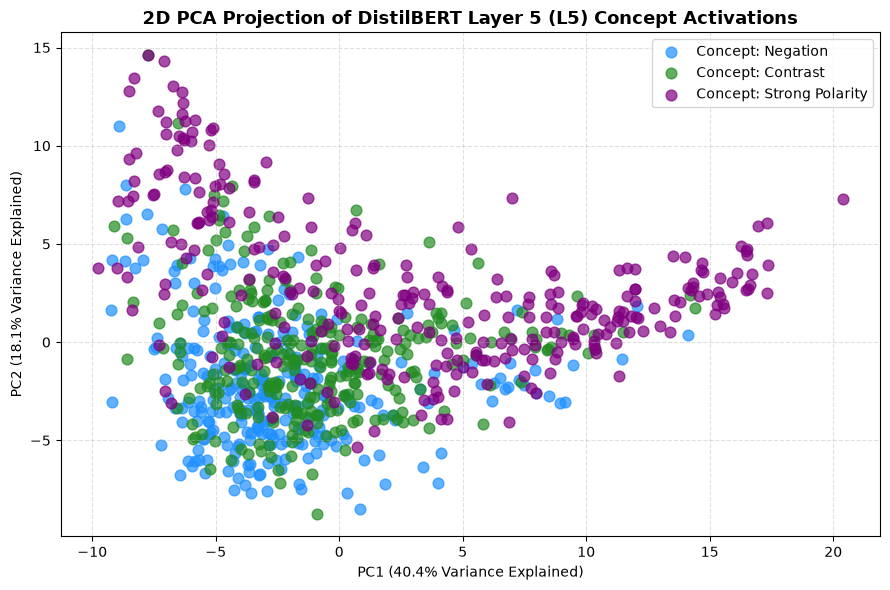

In [13]:
# ===================================================================================
# STEP 2.6: 2D PCA VISUALIZATION OF CONCEPT ACTIVATION SPACES (DISTILBERT ADAPTATION)
# ===================================================================================
from sklearn.decomposition import PCA

# We select the layer to display (e.g., L5 with index 4)
VIS_LAYER_NAME = 'L5'
VIS_LAYER_IDX = TARGET_LAYERS[VIS_LAYER_NAME]

# 1. Extraction of positive texts for each concept from fit_sets
text_neg = fit_sets["has_negation"][fit_sets["has_negation"]["concept_y"] == 1]["text"].tolist()
text_con = fit_sets["has_contrast"][fit_sets["has_contrast"]["concept_y"] == 1]["text"].tolist()
text_pol = fit_sets["has_strong_polarity"][fit_sets["has_strong_polarity"]["concept_y"] == 1]["text"].tolist()

# 2. Extract mean-pooled activations for all layers
acts_neg_all = extract_mean_pooled_layers(text_neg, batch_size=64)
acts_con_all = extract_mean_pooled_layers(text_con, batch_size=64)
acts_pol_all = extract_mean_pooled_layers(text_pol, batch_size=64)

# We select the activations related to the chosen layer
acts_neg = acts_neg_all[VIS_LAYER_IDX]
acts_con = acts_con_all[VIS_LAYER_IDX]
acts_pol = acts_pol_all[VIS_LAYER_IDX]

# 3. Concatenation and calculation of 2D PCA projections
all_vis_acts = np.vstack([acts_neg, acts_con, acts_pol])
pca = PCA(n_components=2, random_state=SEED)
pca_proj = pca.fit_transform(all_vis_acts)

n1, n2, n3 = len(acts_neg), len(acts_con), len(acts_pol)
pca_neg = pca_proj[:n1]
pca_con = pca_proj[n1 : n1 + n2]
pca_pol = pca_proj[n1 + n2 :]

# 4. Plotting with alpha transparency to highlight overlaps
plt.figure(figsize=(9, 6))
plt.scatter(pca_neg[:, 0], pca_neg[:, 1], c='dodgerblue', label='Concept: Negation', s=60, alpha=0.7)
plt.scatter(pca_con[:, 0], pca_con[:, 1], c='forestgreen', label='Concept: Contrast', s=60, alpha=0.7)
plt.scatter(pca_pol[:, 0], pca_pol[:, 1], c='purple', label='Concept: Strong Polarity', s=60, alpha=0.7)

plt.title(f"2D PCA Projection of DistilBERT Layer {VIS_LAYER_IDX + 1} ({VIS_LAYER_NAME}) Concept Activations", fontsize=13, fontweight='bold')
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} Variance Explained)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} Variance Explained)")
plt.legend(frameon=True, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# Step 3: Concept Direction Learning & TCAV Evaluation

This step addresses Requirement 3: **"Learn concept directions from labelled examples, keeping concept fitting and evaluation separate."**

To strictly prevent data leakage and ensure unbiased concept interpretation, the pipeline enforces a clear operational separation between **Concept Direction Fitting** and **TCAV Evaluation**:
1. Concept Direction Fitting (Training Phase)
2. TCAV & Directional Sensitivity Computation (Evaluation Phase)
3. Visualizations

In [14]:
# ==============================================================================
# STEP 3.1: DIRECTIONAL DERIVATIVE & METRIC COMPUTATION ENGINE
# ==============================================================================

def compute_directional_derivatives_with_metadata(df_target, target_class, layer_module_idx, cav_vector, concept_col=None, batch_size=32):
    """
    Computes directional derivatives S_{C,k,l}(x) = grad(f_C(x)) . v_C^l
    for all samples in df_target belonging to target_class.
    Returns derivative array and corresponding concept binary indicators.
    """
    sub_df = df_target[df_target["enc_label"] == target_class].reset_index(drop=True)
    texts = sub_df["text"].tolist()
    concept_vals = sub_df[concept_col].to_numpy() if (concept_col and concept_col in sub_df.columns) else None

    if len(texts) == 0:
        return np.array([]), np.array([])

    cav_tensor = torch.tensor(cav_vector, dtype=torch.float32, device=device)
    dir_derivatives = []

    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start : start + batch_size]
        enc = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt",
        ).to(device)

        layer_output = []
        def hook_fn(module, input, output):
            h = output[0] if isinstance(output, tuple) else output
            h.retain_grad()
            layer_output.append(h)

        handle = model.distilbert.transformer.layer[layer_module_idx].register_forward_hook(hook_fn)
        outputs = model(**enc)
        logits = outputs.logits
        handle.remove()

        h_layer = layer_output[0]
        mask = enc["attention_mask"].unsqueeze(-1).float()
        valid_tokens = mask.sum(dim=1).clamp(min=1.0)

        for i in range(len(batch_texts)):
            model.zero_grad()
            target_logit = logits[i, target_class]
            
            grad_h = torch.autograd.grad(
                outputs=target_logit,
                inputs=h_layer,
                retain_graph=True,
                create_graph=False,
            )[0]

            mask_i = mask[i]
            valid_tokens_i = valid_tokens[i]
            grad_pooled = (grad_h[i] * mask_i).sum(dim=0) / valid_tokens_i

            s_val = torch.dot(grad_pooled, cav_tensor).item()
            dir_derivatives.append(s_val)

    return np.array(dir_derivatives), concept_vals

print("Directional derivative evaluation engine configured successfully.")

Directional derivative evaluation engine configured successfully.


In [15]:
# ==============================================================================
# STEP 3.2: EVALUATION ON TEST SET & METRICS CALCULATION
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. FIT CONCEPT CAVS & RANDOM CONTROL CAVS FOR TARGET LAYERS
# ------------------------------------------------------------------------------
print("Fitting Concept CAVs and Random Control CAVs for selected target layers...")
concept_cavs = {c: {} for c in concepts}
random_cavs_list = []
N_RANDOM_RUNS = 5  # Number of random CAV sets for baseline control

# Training of Concept CAVs on balanced fit_sets
fit_activations = {}
for c_name in concepts:
    f_df = fit_sets[c_name].reset_index(drop=True)
    fit_acts_all = extract_mean_pooled_layers(f_df["text"].tolist(), batch_size=64)
    y_fit = f_df["concept_y"].to_numpy()
    fit_activations[c_name] = (fit_acts_all, y_fit)
    
    for l_name, l_idx in TARGET_LAYERS.items():
        X_fit = fit_acts_all[l_idx]
        cav_vec, _ = fit_cav_direction(X_fit, y_fit, seed=SEED)
        concept_cavs[c_name][l_name] = cav_vec

# Training of Random Control CAVs (with shuffled labels)
for r_idx in range(N_RANDOM_RUNS):
    r_cavs = {}
    r_seed = SEED + 100 + r_idx
    rng = np.random.default_rng(r_seed)
    
    c_ref = concepts[0]
    fit_acts_all, y_fit = fit_activations[c_ref]
    y_shuffled = rng.permutation(y_fit)
    
    for l_name, l_idx in TARGET_LAYERS.items():
        X_fit = fit_acts_all[l_idx]
        r_cav_vec, _ = fit_cav_direction(X_fit, y_shuffled, seed=r_seed)
        r_cavs[l_name] = r_cav_vec
        
    random_cavs_list.append(r_cavs)

print("CAVs fitted successfully. Evaluating directional derivatives on test split...\n")

# ------------------------------------------------------------------------------
# 2. DIRECTIONAL DERIVATIVES & METRICS EVALUATION LOOP
# ------------------------------------------------------------------------------
eval_df = df_test.sample(n=min(600, len(df_test)), random_state=SEED).reset_index(drop=True)
tcav_results = []

for c_name in concepts:
    for target_cls in range(3):
        cls_name = model.config.id2label[target_cls]
        for l_name, l_idx in TARGET_LAYERS.items():
            # Extract Concept CAV
            cav_vec = concept_cavs[c_name].get(l_name, concept_cavs[c_name].get(l_idx + 1))
            dir_ders, concept_flags = compute_directional_derivatives_with_metadata(
                eval_df, target_cls, l_idx, cav_vec, concept_col=c_name
            )

            if len(dir_ders) == 0:
                continue

            # Concept metrics
            tcav_frac = np.mean(dir_ders > 0)
            mean_sens = np.mean(dir_ders)

            # Stratified sensitivities
            mask_c1 = (concept_flags == 1)
            mask_c0 = (concept_flags == 0)

            sens_c1 = np.mean(dir_ders[mask_c1]) if (mask_c1 is not None and np.sum(mask_c1) > 0) else 0.0
            sens_c0 = np.mean(dir_ders[mask_c0]) if (mask_c0 is not None and np.sum(mask_c0) > 0) else 0.0

            # Random Control CAV baseline metrics
            rnd_fracs = []
            rnd_means = []
            for r_cavs in random_cavs_list:
                r_vec = r_cavs.get(l_name, r_cavs.get(l_idx + 1))
                r_ders, _ = compute_directional_derivatives_with_metadata(
                    eval_df, target_cls, l_idx, r_vec
                )
                if len(r_ders) > 0:
                    rnd_fracs.append(np.mean(r_ders > 0))
                    rnd_means.append(np.mean(r_ders))

            rnd_frac_avg = float(np.mean(rnd_fracs)) if len(rnd_fracs) > 0 else 0.0
            mean_rnd_avg = float(np.mean(rnd_means)) if len(rnd_means) > 0 else 0.0

            tcav_results.append({
                "concept": c_name,
                "class": cls_name,
                "class_idx": target_cls,
                "layer": l_name,
                "layer_idx": l_idx,
                "tcav_frac>0": round(float(tcav_frac), 4),
                "rnd_frac>0": round(float(rnd_frac_avg), 4),
                "mean_sens": round(float(mean_sens), 4),
                "mean_rnd": round(float(mean_rnd_avg), 4),
                "sens(c=1)": round(float(sens_c1), 4),
                "sens(c=0)": round(float(sens_c0), 4)
            })

tcav_df = pd.DataFrame(tcav_results)

print("=== Summary of Concept Importance & Sensitivity Metrics across Target Layers ===")
print(tcav_df[[
    "concept", "class", "layer", 
    "tcav_frac>0", "rnd_frac>0", 
    "mean_sens", "mean_rnd", 
    "sens(c=1)", "sens(c=0)"
]].to_string(index=False))

Fitting Concept CAVs and Random Control CAVs for selected target layers...
CAVs fitted successfully. Evaluating directional derivatives on test split...

=== Summary of Concept Importance & Sensitivity Metrics across Target Layers ===
            concept    class layer  tcav_frac>0  rnd_frac>0  mean_sens  mean_rnd  sens(c=1)  sens(c=0)
       has_negation positive    L2       0.1068      0.5155    -0.0049    0.0002    -0.0002    -0.0059
       has_negation positive    L4       0.1019      0.5097    -0.0015    0.0000    -0.0019    -0.0014
       has_negation positive    L5       0.0291      0.6350    -0.0004    0.0001    -0.0004    -0.0005
       has_negation positive    L6       0.0000      0.5456    -0.0011    0.0000    -0.0005    -0.0012
       has_negation  neutral    L2       0.9608      0.6892     0.0021    0.0003     0.0016     0.0021
       has_negation  neutral    L4       1.0000      0.7941     0.0016    0.0003     0.0019     0.0015
       has_negation  neutral    L5       1.0

In [16]:
# ==============================================================================
# STEP 3.3: TOP-N MOST SENSITIVE TEXT INSTANCES VISUALIZATION
# Iterate over all target classes (positive, neutral, negative) and concepts
# ==============================================================================

def visualize_top_influences_text(eval_df, derivatives, concept_name, target_class_name, top_n=3):
    """
    Displays the top_n text instances with the highest directional derivative for a given concept.
    """
    top_idx = np.argsort(derivatives)[-top_n:][::-1]
    print("\n" + "=" * 80)
    print(f"Top {top_n} Text Instances — '{concept_name}' Influence (Target Class: '{target_class_name}')")
    print("=" * 80)
    
    for rank, idx in enumerate(top_idx, 1):
        row = eval_df.iloc[idx]
        text_snippet = row["text"]
        has_concept = row.get(concept_name, "N/A")
        deriv_val = derivatives[idx]
        
        print(f"[{rank}] Derivative: {deriv_val:+.4f} | Concept Present ({concept_name}): {has_concept}")
        print(f"    Text: \"{text_snippet}\"")
        print("-" * 80)

# Select target layer for qualitative inspection (e.g., L6 with index 5)
sample_layer_name = list(TARGET_LAYERS.keys())[-1]   # 'L6'
sample_layer_idx = TARGET_LAYERS[sample_layer_name]   # 5

# Iterate through all sentiment classes: positive, neutral, and negative
for target_class_name, target_class_idx in LABEL_MAP.items():
    print("\n" + "#" * 80)
    print(f"  TARGET CLASS: {target_class_name.upper()} (Label Index: {target_class_idx})")
    print("#" * 80)
    
    # Filter eval_df for the specific target class to keep derivatives aligned
    sub_eval_df = eval_df[eval_df["enc_label"] == target_class_idx].reset_index(drop=True)
    
    # Skip iteration if no samples exist for the current class
    if len(sub_eval_df) == 0:
        print(f"No samples found in eval_df for class '{target_class_name}'. Skipping...")
        continue
    
    # Inspect top sensitive instances across all concepts for the current class
    for c_name in concepts:
        cav_vec = concept_cavs[c_name][sample_layer_name]
        derivs, _ = compute_directional_derivatives_with_metadata(
            sub_eval_df, target_class_idx, sample_layer_idx, cav_vec, concept_col=c_name
        )
        visualize_top_influences_text(sub_eval_df, derivs, c_name, target_class_name, top_n=3)


################################################################################
  TARGET CLASS: POSITIVE (Label Index: 0)
################################################################################

Top 3 Text Instances — 'has_negation' Influence (Target Class: 'positive')
[1] Derivative: -0.0000 | Concept Present (has_negation): 1
    Text: "My girlfriend and I could not believe that this tiny place lived up to the hype."
--------------------------------------------------------------------------------
[2] Derivative: -0.0001 | Concept Present (has_negation): 1
    Text: "If you have a kid who likes LEGO but you don't want to spend hundreds of dollars on a handful of pieces, come here for large misc bags for $20 or a pick-n-mix selection starting at something like $5 for a salad bowl container."
--------------------------------------------------------------------------------
[3] Derivative: -0.0002 | Concept Present (has_negation): 0
    Text: "The Pineville location has picked 

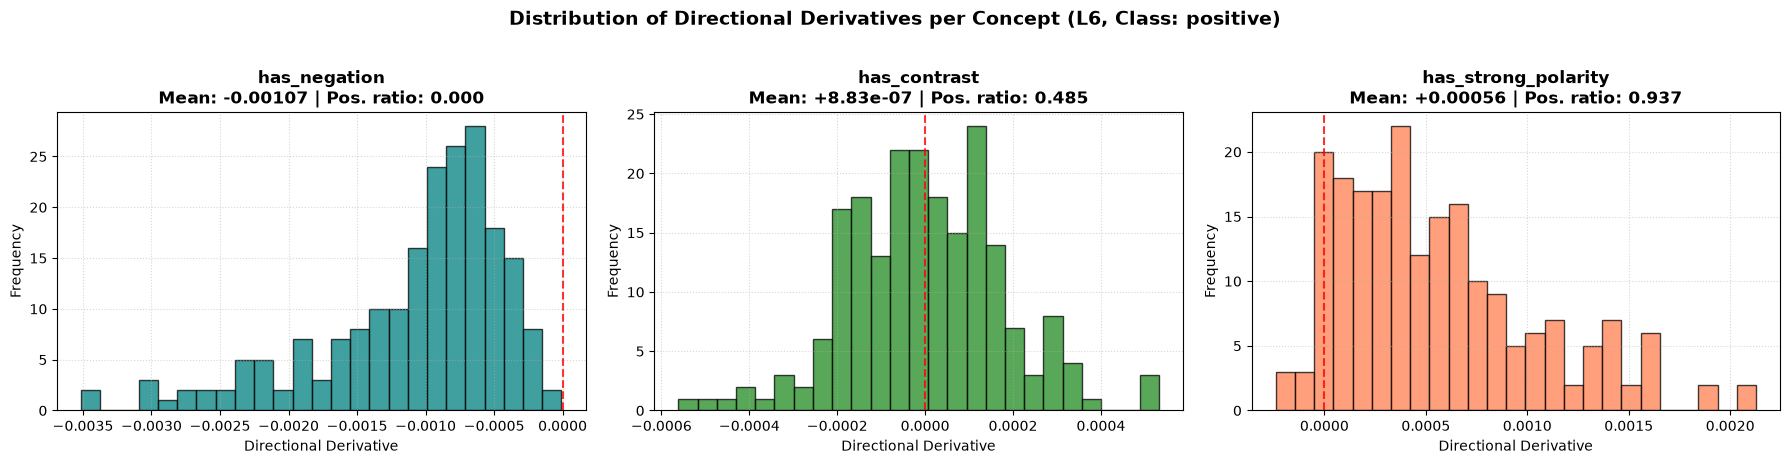

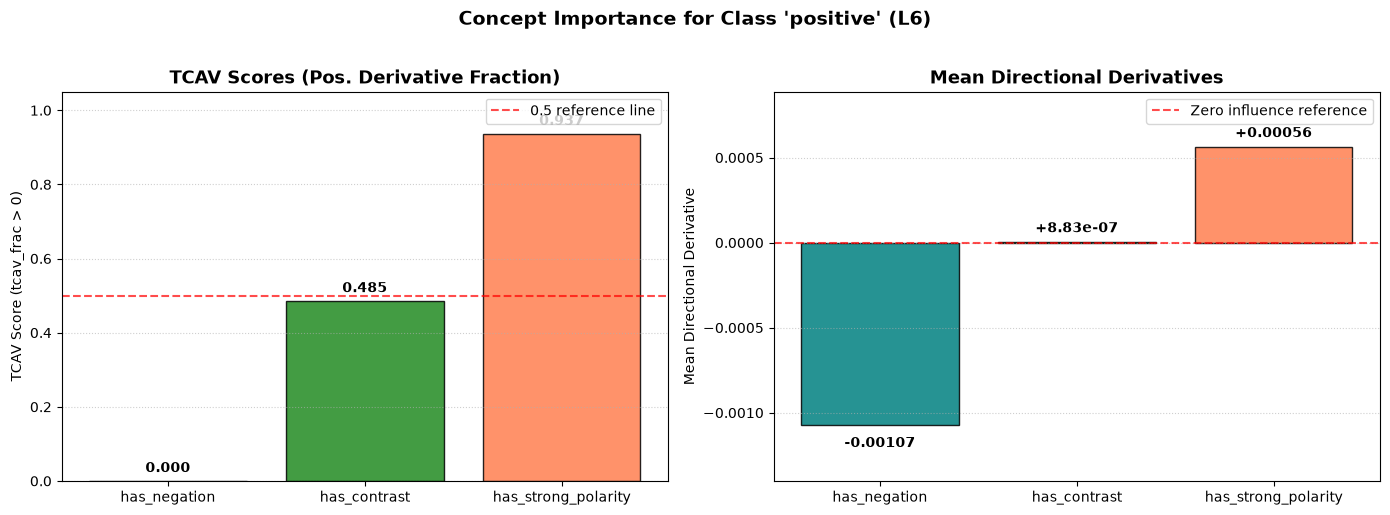

In [17]:
# ==============================================================================
# STEP 3.4: CONCEPT DISTRIBUTION & IMPORTANCE PLOTS
# ==============================================================================

# 1. Select target layer and target sentiment class for detailed analysis
target_layer_str = list(TARGET_LAYERS.keys())[-1]  # e.g., 'L6'
target_layer_idx = TARGET_LAYERS[target_layer_str] # e.g., 5

target_cls_idx = 0  # 0: positive (1: neutral, 2: negative)
target_cls_name = model.config.id2label[target_cls_idx]

# 2. Extract directional derivatives for each concept on the target layer & class
derivs_list = []
for c_name in concepts:
    cav_vec = concept_cavs[c_name][target_layer_str]
    dir_ders, _ = compute_directional_derivatives_with_metadata(
        eval_df, target_cls_idx, target_layer_idx, cav_vec, concept_col=c_name
    )
    derivs_list.append(dir_ders)

# Calculate TCAV scores (Pos. Derivative Fraction) and Mean Derivatives
tcav_scores = [float(np.mean(d > 0)) if len(d) > 0 else 0.0 for d in derivs_list]
mean_derivs = [float(np.mean(d)) if len(d) > 0 else 0.0 for d in derivs_list]
colors = ['teal', 'forestgreen', 'coral']

# ------------------------------------------------------------------------------
# 1. Distribution of directional derivatives per concept
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, len(concepts), figsize=(6 * len(concepts), 4.5))
if len(concepts) == 1:
    axes = [axes]

for ax, concept, derivs, color in zip(axes, concepts, derivs_list, colors):
    ax.hist(derivs, bins=25, alpha=0.75, color=color, edgecolor='black')
    ax.axvline(0, color='red', linestyle='--', alpha=0.8, linewidth=1.5)
    mean_val = np.mean(derivs) if len(derivs) > 0 else 0.0
    pos_ratio = np.mean(derivs > 0) if len(derivs) > 0 else 0.0
    ax.set_title(f"{concept}\nMean: {mean_val:+.3g} | Pos. ratio: {pos_ratio:.3f}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Directional Derivative")
    ax.set_ylabel("Frequency")
    ax.grid(True, linestyle=':', alpha=0.5)

plt.suptitle(f"Distribution of Directional Derivatives per Concept ({target_layer_str}, Class: {target_cls_name})", 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 2. Side-by-side Bar plots for TCAV scores and Mean Derivatives
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: TCAV Scores (Fraction > 0)
bars1 = axes[0].bar(concepts, tcav_scores, color=colors, alpha=0.85, edgecolor='black')
axes[0].axhline(0.5, color='red', linestyle='--', alpha=0.7, label='0.5 reference line')
axes[0].set_ylim(0, 1.05)
axes[0].set_title("TCAV Scores (Pos. Derivative Fraction)", fontsize=13, fontweight='bold')
axes[0].set_ylabel("TCAV Score (tcav_frac > 0)")
axes[0].legend(loc='upper right')
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

for bar, score in zip(bars1, tcav_scores):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015,
                 f'{score:.3f}', ha='center', va='bottom', fontweight='bold')

# Right plot: Mean Directional Derivatives
bars2 = axes[1].bar(concepts, mean_derivs, color=colors, alpha=0.85, edgecolor='black')
axes[1].axhline(0, color='red', linestyle='--', alpha=0.7, label='Zero influence reference')
axes[1].set_title("Mean Directional Derivatives", fontsize=13, fontweight='bold')
axes[1].set_ylabel("Mean Directional Derivative")
axes[1].legend(loc='upper right')
axes[1].grid(axis='y', linestyle=':', alpha=0.6)

for bar, val in zip(bars2, mean_derivs):
    axes[1].annotate(f'{val:+.3g}',
                     xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                     xytext=(0, 5 if val >= 0 else -8), textcoords='offset points',
                     ha='center', va='bottom' if val >= 0 else 'top', fontweight='bold')

axes[1].margins(y=0.2)
plt.suptitle(f"Concept Importance for Class '{target_cls_name}' ({target_layer_str})", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Step 4: Concept Detection, Class-Score Sensitivity & Controls

In this step, we evaluate the statistical reliability of the Concept Activation Vectors (CAVs) against random/shuffled baselines, measure class-score sensitivity via TCAV directional derivatives with two-sample $t$-tests, and execute targeted lexical interventions to monitor directional logit shifts.

In [18]:
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind
from sklearn.linear_model import LogisticRegression
import torch

# Configuration for controls and target setup
if isinstance(TARGET_LAYERS, dict):
  target_layer_dict = TARGET_LAYERS
else:
  layer_map = {'L1': 0, 'L2': 1, 'L3': 2, 'L4': 3, 'L5': 4, 'L6': 5}
  target_layer_dict = {l: layer_map[l] for l in TARGET_LAYERS}

CONCEPTS = ['has_negation', 'has_contrast', 'has_strong_polarity']
N_RANDOM_RUNS = 20  # Number of random CAV controls for statistical testing

# Map class names to label indices matching DistilBERT configuration
LABEL_MAP = {'positive': 0, 'neutral': 1, 'negative': 2}
CLASS_NAMES = ['negative', 'neutral', 'positive']

# Ensure evaluation dataframe and activations exist from previous steps
if 'eval_df' not in globals():
  eval_df = df_test.reset_index(drop=True)

if 'fit_activations' not in globals():
  fit_activations = {}
  for concept in CONCEPTS:
    f_df = fit_sets[concept].reset_index(drop=True)
    fit_acts_all = extract_mean_pooled_layers(
        f_df['text'].tolist(), batch_size=64
    )
    y_fit = f_df['concept_y'].to_numpy()
    fit_activations[concept] = (fit_acts_all, y_fit)

print('=== Step 4.1: Concept Detection Quality & CAV Validation ===')


def train_cav_classifier(pos_acts, neg_acts):
  """Trains a linear Logistic Regression to extract the orthogonal normal vector (CAV)."""
  X = np.vstack([pos_acts, neg_acts])
  y = np.array([1] * len(pos_acts) + [0] * len(neg_acts))

  clf = LogisticRegression(max_iter=1000, solver='liblinear')
  clf.fit(X, y)

  # CAV vector (orthogonal normal to decision boundary) and fitting accuracy
  cav = clf.coef_[0]
  acc = clf.score(X, y)
  return cav, acc


# 1. Evaluate CAV concept detection accuracy vs Shuffled Label Controls across target layers
detection_results = []
cav_dict = {}

for layer, l_idx in target_layer_dict.items():
  cav_dict[layer] = {}
  for concept in CONCEPTS:
    # Extract pooled activations from concept fitting set
    fit_acts_all, y_fit = fit_activations[concept]
    pos_acts = fit_acts_all[l_idx][y_fit == 1]
    neg_acts = fit_acts_all[l_idx][y_fit == 0]

    # True concept vector & accuracy
    real_cav, real_acc = train_cav_classifier(pos_acts, neg_acts)
    cav_dict[layer][concept] = real_cav

    # Shuffled label control baseline
    X_all = np.vstack([pos_acts, neg_acts])
    y_shuffled = np.array([1] * len(pos_acts) + [0] * len(neg_acts))
    np.random.seed(42)
    np.random.shuffle(y_shuffled)

    clf_shuffled = LogisticRegression(
        max_iter=1000, solver='liblinear'
    ).fit(X_all, y_shuffled)
    shuffled_acc = clf_shuffled.score(X_all, y_shuffled)

    detection_results.append({
        'layer': layer,
        'concept': concept,
        'real_cav_acc': round(real_acc, 4),
        'shuffled_label_acc': round(shuffled_acc, 4),
        'delta_acc': round(real_acc - shuffled_acc, 4),
    })

detection_df = pd.DataFrame(detection_results)
print('\n[Concept Detection Quality vs. Shuffled Baseline]')
print(detection_df.to_string(index=False))

print(
    '\n=== Step 4.2: TCAV Class-Score Sensitivity & Statistical Significance'
    ' ==='
)

# 2. Compute Directional Derivatives & Perform Statistical t-tests against Random CAV Controls
tcav_stat_results = []

for layer, l_idx in target_layer_dict.items():
  for concept in CONCEPTS:
    real_cav = cav_dict[layer][concept]

    # Generate random CAV controls on fit activations
    fit_acts_all, _ = fit_activations[concept]
    combined_acts = fit_acts_all[l_idx]

    random_cavs = []
    for r in range(N_RANDOM_RUNS):
      np.random.seed(100 + r)
      rand_y = np.random.randint(0, 2, size=len(combined_acts))
      clf_rand = LogisticRegression(
          max_iter=1000, solver='liblinear'
      ).fit(combined_acts, rand_y)
      random_cavs.append(clf_rand.coef_[0])

    for class_name in CLASS_NAMES:
      class_idx = LABEL_MAP[class_name]

      # Compute directional derivatives using test gradients / auto-grad pipeline
      if 'test_gradients' in globals() and layer in test_gradients:
        test_grads = test_gradients[layer][class_name]
        real_dir_derivs = np.dot(test_grads, real_cav)
      else:
        real_dir_derivs, _ = compute_directional_derivatives_with_metadata(
            eval_df, target_class=class_idx, layer_module_idx=l_idx, cav_vector=real_cav
        )

      tcav_score = np.mean(real_dir_derivs > 0)

      # Directional derivatives for random CAV controls
      rand_tcav_scores = []
      rand_dir_derivs_list = []

      for rand_cav in random_cavs:
        if 'test_gradients' in globals() and layer in test_gradients:
          rand_derivs = np.dot(test_grads, rand_cav)
        else:
          rand_derivs, _ = compute_directional_derivatives_with_metadata(
              eval_df, target_class=class_idx, layer_module_idx=l_idx, cav_vector=rand_cav
          )
        rand_tcav_scores.append(np.mean(rand_derivs > 0))
        rand_dir_derivs_list.extend(rand_derivs)

      # Perform Two-Sample t-test between real derivatives and random controls
      t_stat, p_val = ttest_ind(
          real_dir_derivs, rand_dir_derivs_list, equal_var=False
      )

      tcav_stat_results.append({
          'layer': layer,
          'concept': concept,
          'class': class_name,
          'tcav_score': round(float(tcav_score), 4),
          'mean_random_tcav': round(float(np.mean(rand_tcav_scores)), 4),
          't_statistic': round(float(t_stat), 3),
          'p_value': round(float(p_val), 5),
          'significant_p_05': p_val < 0.05,
      })

tcav_stat_df = pd.DataFrame(tcav_stat_results)
print('\n[TCAV Sensitivity & Statistical Significance vs. Random CAV Controls]')
print(tcav_stat_df.head(15).to_string(index=False))

=== Step 4.1: Concept Detection Quality & CAV Validation ===

[Concept Detection Quality vs. Shuffled Baseline]
layer             concept  real_cav_acc  shuffled_label_acc  delta_acc
   L2        has_negation        0.9983              0.9250     0.0733
   L2        has_contrast        0.9967              0.9267     0.0700
   L2 has_strong_polarity        0.9900              0.9133     0.0767
   L4        has_negation        1.0000              0.9400     0.0600
   L4        has_contrast        0.9983              0.9433     0.0550
   L4 has_strong_polarity        0.9933              0.9433     0.0500
   L5        has_negation        0.9983              0.9333     0.0650
   L5        has_contrast        0.9983              0.9367     0.0617
   L5 has_strong_polarity        0.9917              0.9533     0.0383
   L6        has_negation        0.9850              0.8233     0.1617
   L6        has_contrast        0.9650              0.8067     0.1583
   L6 has_strong_polarity        0.9

The real TCAV is almost always better than random baseline.

In [19]:
# Set model to evaluation mode
model.eval()

# Retrieve class label mapping from model config (falling back to standard indices if needed)
if hasattr(model.config, "id2label") and model.config.id2label:
  id2label = model.config.id2label
else:
  id2label = {0: "negative", 1: "neutral", 2: "positive"}

# Defined minimal pair edits for qualitative and numerical sensitivity checks
input_edits = [
    {
        "id": 4148,
        "concept": "has_negation",
        "edit_type": "replace_neg_clause",
        "orig_text": (
            "We tried a new place. Not worth the price, wait, or probable"
            " health risks."
        ),
        "edited_text": (
            "We tried a new place. It is worth the price, wait, and probable"
            " health risks."
        ),
        "expected": "up_pos / down_neg",
    },
    {
        "id": 4335,
        "concept": "has_negation",
        "edit_type": "remove_not",
        "orig_text": (
            "A minute later, the TV will go up several channels like it's"
            " possessed. Which is not good."
        ),
        "edited_text": (
            "A minute later, the TV will go up several channels like it's"
            " possessed. Which is good."
        ),
        "expected": "up_pos / down_neg",
    },
    {
        "id": 409,
        "concept": "has_negation",
        "edit_type": "neither_nor -> both_and",
        "orig_text": (
            "Alas, neither she nor I were able to find a new pair in my size."
        ),
        "edited_text": (
            "Alas, both she and I were able to find a new pair in my size."
        ),
        "expected": "down_neg / shift_neu_or_pos",
    },
    {
        "id": 3705,
        "concept": "has_contrast",
        "edit_type": "but -> and",
        "orig_text": (
            "The place was quaint but the waiter was rude and the food was"
            " terrible."
        ),
        "edited_text": (
            "The place was quaint and the waiter was rude and the food was"
            " terrible."
        ),
        "expected": "smaller_contrast (neg stays high)",
    },
    {
        "id": 163,
        "concept": "has_contrast",
        "edit_type": "drop_although",
        "orig_text": (
            "Although they are branded as a Mitsubishi Dealership, they carry"
            " high end used cars and act as a used car dealership on the side."
        ),
        "edited_text": (
            "They are branded as a Mitsubishi Dealership, they carry high end"
            " used cars and act as a used car dealership on the side."
        ),
        "expected": "shift_from_neu_or_d_logit",
    },
    {
        "id": 4227,
        "concept": "has_contrast",
        "edit_type": "but -> and",
        "orig_text": "A little dry and chewy, but that's just to my taste!",
        "edited_text": "A little dry and chewy, and that's just to my taste!",
        "expected": "change_polarity_balance",
    },
    {
        "id": 3912,
        "concept": "has_strong_polarity",
        "edit_type": "awesome -> ok",
        "orig_text": (
            "If you like high prices and crowds, Container Park is awesome."
        ),
        "edited_text": "If you like high prices and crowds, Container Park is ok.",
        "expected": "shift_neu / down_pos",
    },
    {
        "id": 3966,
        "concept": "has_strong_polarity",
        "edit_type": "amazing -> decent",
        "orig_text": (
            "Is it even fair to expect a fish place would have amazing wings?"
        ),
        "edited_text": (
            "Is it even fair to expect a fish place would have decent wings?"
        ),
        "expected": "shift_neu / less_extreme_logit",
    },
    {
        "id": 3957,
        "concept": "has_strong_polarity",
        "edit_type": "excellent -> good",
        "orig_text": (
            "It was excellent and huge portions I had forgotten I had spent the"
            " night on the toilet."
        ),
        "edited_text": (
            "It was good and huge portions I had forgotten I had spent the"
            " night on the toilet."
        ),
        "expected": "down_pos / shift_neg",
    },
]


def predict_logits_and_probs(texts, batch_size=32, max_length=128):
  """Computes unnormalized logits and softmax probabilities for input texts in batches."""
  all_logits, all_probs = [], []
  with torch.no_grad():
    for start in range(0, len(texts), batch_size):
      enc = tokenizer(
          texts[start : start + batch_size],
          padding=True,
          truncation=True,
          max_length=max_length,
          return_tensors="pt",
      ).to(device)
      logits = model(**enc).logits
      probs = torch.softmax(logits, dim=-1)
      all_logits.append(logits.cpu())
      all_probs.append(probs.cpu())
  return torch.cat(all_logits, dim=0), torch.cat(all_probs, dim=0)


# Predict on original vs edited texts
orig_logits, orig_probs = predict_logits_and_probs(
    [x["orig_text"] for x in input_edits]
)
edit_logits, edit_probs = predict_logits_and_probs(
    [x["edited_text"] for x in input_edits]
)

# Process results and extract logit differences across all sentiment classes
rows = []
for i, item in enumerate(input_edits):
  l0, l1 = orig_logits[i], edit_logits[i]
  p0, p1 = orig_probs[i], edit_probs[i]

  # Fetch string predictions using integer keys mapping
  pred0_idx = int(torch.argmax(l0).item())
  pred1_idx = int(torch.argmax(l1).item())
  pred0 = id2label.get(pred0_idx, str(pred0_idx))
  pred1 = id2label.get(pred1_idx, str(pred1_idx))

  # Map differences explicitly assuming order [negative, neutral, positive] or model logit order
  rows.append({
      "id": item["id"],
      "concept": item["concept"],
      "edit": item["edit_type"],
      "expected": item["expected"],
      "pred": f"{pred0}->{pred1}",
      "d_neg": round(float((l1[0] - l0[0]).item()), 3),
      "d_neu": round(float((l1[1] - l0[1]).item()), 3),
      "d_pos": round(float((l1[2] - l0[2]).item()), 3),
  })

# Display formatted lexical control results
edits_res_df = pd.DataFrame(rows)
print("\n[Lexical Interventions & Directional Logit Shift Analysis]")
print(edits_res_df.to_string(index=False))


[Lexical Interventions & Directional Logit Shift Analysis]
  id             concept                    edit                          expected               pred  d_neg  d_neu  d_pos
4148        has_negation      replace_neg_clause                 up_pos / down_neg negative->positive  2.260 -0.988 -1.558
4335        has_negation              remove_not                 up_pos / down_neg negative->positive  3.732 -0.555 -3.619
 409        has_negation neither_nor -> both_and       down_neg / shift_neu_or_pos negative->positive  0.400 -0.301 -0.133
3705        has_contrast              but -> and smaller_contrast (neg stays high) negative->negative -0.175 -0.165  0.366
 163        has_contrast           drop_although         shift_from_neu_or_d_logit positive->positive  0.199 -0.239  0.035
4227        has_contrast              but -> and           change_polarity_balance positive->positive -0.083 -0.173  0.229
3912 has_strong_polarity           awesome -> ok              shift_neu / down_

Negation Interventions flips predictions from negative to positive, confirming that negation tokens act as a direct causal trigger in the model's sentiment classification.  
On the other hand, Contrast and Strong Polarity Interventions bring no prediction change, so the effect is weaker, but the logit magnitudes are correctly pushed into the right directions.  